# 03 · LLM event extraction: turning news headlines into an event calendar

<a href="https://colab.research.google.com/github/FarhanRajputFelix/saans/blob/main/notebooks/03_llm_event_calendar.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Smog is shaped by events no sensor records: school closures, traffic bans, "green lockdowns", fireworks nights. They exist only as news. This notebook uses a Large Language Model (**Gemini**, with **Groq** as an automatic fallback; see `saans/llm.py`) as a **data-pipeline tool**: it reads real, dated headlines and returns structured JSON records, which become calendar features for the model.

Guardrails:
* the LLM only **reads** headlines; every event keeps the ID and link of the headline it came from;
* temperature 0 and a strict JSON format, so the output is repeatable and machine-checkable;
* every answer is cached (`data/llm_cache/`), so re-running costs nothing;
* a random sample of 20 events is checked against its headlines and the accuracy is reported.

**Setup.** Runs the same way locally and in Google Colab. In Colab it clones the repo (which includes the cleaned data) and reads API keys from Colab's *Secrets* panel (key icon on the left).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/saans"):
        subprocess.run(["git", "clone", "-q", "https://github.com/FarhanRajputFelix/saans.git", "/content/saans"], check=True)
    os.chdir("/content/saans")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap", "python-dotenv"], check=True)
    from google.colab import userdata
    for k in ["OPENAQ_API_KEY", "FIRMS_MAP_KEY", "GEMINI_API_KEY", "GROQ_API_KEY"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception:
            pass
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # work from the repo root so `saans` and `data/` resolve
sys.path.insert(0, os.getcwd())

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from saans.config import INTERIM, PROCESSED, REPORTS, LOCAL_TZ, CITIES
from saans import llm, viz

viz.use_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 110)

news = pd.read_csv(INTERIM / "news_headlines.csv", parse_dates=["time_utc"])
news["date_pkt"] = news.time_utc.dt.tz_convert(LOCAL_TZ).dt.date.astype(str)
news = news.reset_index(drop=True)
news["hid"] = news.index
print(f"{len(news):,} headlines, {news.date_pkt.min()} to {news.date_pkt.max()}")

2,255 headlines, 2020-01-01 to 2026-01-31


## The extraction prompt

Headlines go to the model in batches of 60. Each comes with its publication date, so the model can resolve phrases like "from tomorrow".

In [3]:
EVENT_TYPES = ["school_closure", "traffic_restriction", "smog_emergency", "lockdown_or_office_closure",
               "construction_or_industry_ban", "crop_burning_ban", "fireworks_night", "other_measure"]
PLACES = ["Lahore", "Faisalabad", "Multan", "Islamabad", "Karachi", "Punjab-wide", "Other", "Unspecified"]

PROMPT = """You extract smog-related events from Pakistani news headlines for an air-quality dataset.

For each headline below, decide whether it reports a CONCRETE action or event that affects air pollution
or people's exposure: e.g. schools closed, traffic or vehicle restrictions, a smog emergency declared,
markets/offices closed or a "green lockdown", construction/industry/kiln bans, crop-burning bans or arrests,
or a fireworks night. Headlines that only report an AQI ranking, a forecast, a court hearing, an opinion,
or health advice are NOT events. A headline about LIFTING, ENDING or RELAXING a measure, or schools REOPENING,
is NOT a new event. Measures unrelated to air pollution (toll tags, fuel-testing labs, technology upgrades) are NOT events.

Return a JSON object {{"events": [...]}} with one item per headline that IS an event, with fields:
  "hid": the headline id (integer, copied exactly),
  "event_type": one of {types},
  "place": one of {places}; use a city or "Punjab-wide" ONLY when the headline names it (a court such as the
           Lahore High Court counts as Punjab-wide); use "Unspecified" when the headline names no place. Never guess,
  "start_date": "YYYY-MM-DD" (use the publication date unless the headline gives another date, e.g. "from Monday"),
  "duration_days": integer number of days if stated or clearly implied, otherwise null.
Do not invent anything that is not in the headline. Headlines that are not events are simply left out.

Headlines (id | published date | headline):
{rows}
"""

def extract(batch: pd.DataFrame) -> tuple[list[dict], str]:
    rows = "\n".join(f"{r.hid} | {r.date_pkt} | {r.title}" for r in batch.itertuples())
    answer, provider = llm.ask(PROMPT.format(types=EVENT_TYPES, places=PLACES, rows=rows), temperature=0.0, as_json=True)
    return llm.parse_json(answer).get("events", []), provider

print(PROMPT.format(types=EVENT_TYPES, places=PLACES, rows="17 | 2024-11-07 | <headline text>")[:1600])

You extract smog-related events from Pakistani news headlines for an air-quality dataset.

For each headline below, decide whether it reports a CONCRETE action or event that affects air pollution
or people's exposure: e.g. schools closed, traffic or vehicle restrictions, a smog emergency declared,
markets/offices closed or a "green lockdown", construction/industry/kiln bans, crop-burning bans or arrests,
or a fireworks night. Headlines that only report an AQI ranking, a forecast, a court hearing, an opinion,
or health advice are NOT events. A headline about LIFTING, ENDING or RELAXING a measure, or schools REOPENING,
is NOT a new event. Measures unrelated to air pollution (toll tags, fuel-testing labs, technology upgrades) are NOT events.

Return a JSON object {"events": [...]} with one item per headline that IS an event, with fields:
  "hid": the headline id (integer, copied exactly),
  "event_type": one of ['school_closure', 'traffic_restriction', 'smog_emergency', 'lockdown_or_offic

In [4]:
# batch within each download window (Oct-Nov / Dec-Jan), so batches stay stable and cached when new windows arrive
d = pd.to_datetime(news.date_pkt)
news["window"] = np.where(d.dt.month >= 10, d.dt.year.astype(str) + np.where(d.dt.month == 12, "-12", "-10"),
                          (d.dt.year - 1).astype(str) + "-12")
events, providers = [], []
for _, w in news.groupby("window", sort=True):
    for start in range(0, len(w), 60):
        found, provider = extract(w.iloc[start:start + 60])
        events += found
        providers.append(provider)
ev = pd.DataFrame(events)
print(f"{len(ev)} events from {len(news)} headlines; providers used: {pd.Series(providers).value_counts().to_dict()}")

394 events from 2255 headlines; providers used: {'gemini:gemini-3.5-flash-lite': 41}


## Validate the model's output before using it

The LLM's JSON is checked like any other raw data: valid IDs, allowed categories, parseable dates within the study period. Invalid rows are dropped and counted.

In [5]:
n = len(ev)
ev = ev[ev.hid.isin(news.hid)]
ev = ev[ev.event_type.isin(EVENT_TYPES) & ev.place.isin(PLACES)]
ev["start_date"] = pd.to_datetime(ev.start_date, errors="coerce")
ev = ev[ev.start_date.between("2019-12-01", "2026-02-28")]
ev["duration_days"] = pd.to_numeric(ev.duration_days, errors="coerce")
ev = ev.drop_duplicates(["hid", "event_type", "place"])
print(f"schema check: {n} -> {len(ev)} events kept")
ev = ev.merge(news[["hid", "title", "domain", "url", "date_pkt"]], on="hid")
ev.event_type.value_counts().to_frame("events")

schema check: 394 -> 387 events kept


,events
event_type,
school_closure,117
other_measure,80
traffic_restriction,58
lockdown_or_office_closure,55
construction_or_industry_ban,46
smog_emergency,26
fireworks_night,3
crop_burning_ban,2


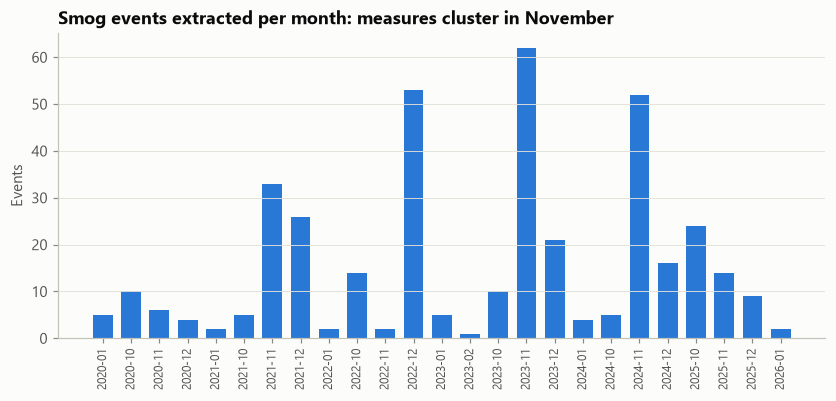

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
counts = ev.groupby([ev.start_date.dt.to_period("M").astype(str)]).size()
ax.bar(counts.index, counts.values, color=viz.SERIES[0], width=0.7)
ax.set(title="Smog events extracted per month: measures cluster in November", ylabel="Events")
ax.tick_params(axis="x", rotation=90, labelsize=8)
fig.savefig(REPORTS / "figures/events_per_month.png", bbox_inches="tight")
plt.show()

## Accuracy check on a random sample of 50 events

Each sampled event is shown next to the headline it came from. The reviewer marks whether the type, place and date are all supported by the headline. The verdicts are stored in `reports/event_extraction_check.csv` and the accuracy is reported with a 95% confidence interval: a sample this size still leaves an uncertainty of roughly +-13 points, which is why it was raised from the first version's 20.

In [7]:
sample = ev.sample(min(50, len(ev)), random_state=42)[["hid", "date_pkt", "title", "event_type", "place", "start_date", "duration_days"]]
check_path = REPORTS / "event_extraction_check.csv"
if check_path.exists():
    verdicts = pd.read_csv(check_path)[["hid", "event_type", "correct", "reviewer_note"]]
    sample = sample.merge(verdicts, on=["hid", "event_type"], how="left")
else:
    sample["correct"], sample["reviewer_note"] = np.nan, ""
    sample.to_csv(check_path, index=False)
sample

,hid,date_pkt,title,event_type,place,start_date,duration_days,correct,reviewer_note
0,1657,2024-11-15,"Punjab announces complete lockdown in Lahore , Multan to tackle smog",lockdown_or_office_closure,Lahore,2024-11-15,NaN,1,correct; Multan is also named but only Lahore was extracted
1,964,2022-12-27,"LHC orders extension in winter vacation of schools , colleges as smog worsens",school_closure,Punjab-wide,2022-12-27,NaN,1,"type, place and date supported by the headline"
2,677,2021-12-29,"Punjab bans fireworks , concerts and aerial firing on New Year night",fireworks_night,Punjab-wide,2021-12-29,NaN,0,"fireworks BAN read as a fireworks night; date should be 31 Dec (New Year night), not publication day"
3,1506,2024-10-23,Punjab announces new school timings,school_closure,Punjab-wide,2024-10-23,NaN,0,new school timings are not a closure
4,1197,2023-11-17,34 factories sealed during anti - smog drive in Faisalabad,construction_or_industry_ban,Faisalabad,2023-11-17,NaN,1,"type, place and date supported by the headline"
5,1609,2024-11-11,"M2 , M3 and other motorways closed at these points due to fog",traffic_restriction,Unspecified,2024-11-11,NaN,1,"motorway closure (fog) counted as a traffic restriction, as in v1"
6,610,2021-12-17,Punjab govt announces winter holidays from Dec 23,school_closure,Punjab-wide,2021-12-17,NaN,0,headline says from Dec 23; start date set to publication day
7,760,2022-10-27,12 pyrolysis plants in Lahore demolished for causing air pollution - Pakistan,construction_or_industry_ban,Lahore,2022-10-27,NaN,1,"type, place and date supported by the headline"
8,1573,2024-11-08,All activities in Lahore schools suspended amid smog holidays,school_closure,Lahore,2024-11-08,NaN,1,"type, place and date supported by the headline"
9,339,2021-11-14,5 anti - smog squads formed to curb pollution in Lahore - Pakistan,other_measure,Lahore,2021-11-14,NaN,1,"type, place and date supported by the headline"


In [8]:
reviewed = sample.correct.notna().sum()
if reviewed:
    acc = sample.correct.astype(float).mean()
    half = 1.96 * np.sqrt(acc * (1 - acc) / reviewed)  # normal-approximation 95% interval
    print(f"Extraction accuracy on {reviewed} reviewed events: {acc:.0%} (95% interval {max(acc - half, 0):.0%} to {min(acc + half, 1):.0%}); "
          "type, place and date must all be supported by the headline")
else:
    print("Sample saved to reports/event_extraction_check.csv; fill the 'correct' column (1/0) and re-run.")

Extraction accuracy on 50 reviewed events: 76% (95% interval 64% to 88%); type, place and date must all be supported by the headline


**How the prompt was improved.** A first version was checked on 20 events and scored 65%. Its misses fell into three groups, and each became a rule in the prompt above:
* **inverted meaning**: "Punjab decides to *lift* smog lockdown" and "schools *reopen*" were read as new closures → lifting, ending or reopening is not an event;
* **inferred place**: "Section 144 imposed" was tagged Punjab-wide although no place is named → a place only when the headline names it, otherwise "Unspecified" (not assigned to any city);
* **not a smog event**: an M-tag toll rule, a kiln technology upgrade, a new fuel lab → measures unrelated to air pollution are not events.

With these rules, the strict check on **50** events scores **76%** (38 of 50; 95% interval about 64-88%), up from 65% on 20 (the samples differ, so the intervals overlap). The remaining 12 errors are of new kinds:
* **future dates missed** (4): "close schools *from Dec 23*" was dated to the publication day;
* **timing changes read as closures** (2): "new school timings";
* **a fireworks ban read as a fireworks night** (2);
* **not a concrete smog measure** (4): a question headline, an EV proposal, a park rule, a statement of intent.

The first version's 20 verdicts are kept in `reports/event_extraction_check_v1.csv`. The event calendar remains a **noisy** signal. That is acceptable because it is a minor feature (the calendar group is about 5% of the model's explanation, notebook 05), and the calendar uses yes/no flags, so three outlets reporting the same closure count once.

## From events to daily calendar flags

An event is "active" from its start date for its stated duration, or **3 days** when the headline gives none (most announced closures in the data run for a few days and are then extended by a new announcement, which is a new event). A **Punjab-wide** measure applies to Lahore, Faisalabad and Multan. Fireworks nights are added for New Year's Eve and the approximate Shab-e-Barat dates.

In [9]:
PUNJAB = ["lahore", "faisalabad", "multan"]
MEASURES = ["school_closure", "traffic_restriction", "smog_emergency", "lockdown_or_office_closure", "construction_or_industry_ban"]
days = pd.date_range("2020-01-01", "2026-01-31", freq="D")
cal = pd.DataFrame([(c, d) for c in CITIES for d in days], columns=["city", "date"])
cal["measures_active"] = 0
cal["crop_burning_ban_active"] = 0
for e in ev.itertuples():
    cities = PUNJAB if e.place == "Punjab-wide" else [e.place.lower()] if e.place.lower() in CITIES else []
    if not cities:
        continue
    dur = int(e.duration_days) if pd.notna(e.duration_days) and 0 < e.duration_days <= 60 else 3
    m = cal.city.isin(cities) & cal.date.between(e.start_date, e.start_date + pd.Timedelta(days=dur - 1))
    if e.event_type in MEASURES:
        cal.loc[m, "measures_active"] = 1  # yes/no: several outlets reporting one closure must not count several times
    elif e.event_type == "crop_burning_ban":
        cal.loc[m, "crop_burning_ban_active"] = 1

fireworks = pd.to_datetime(["2020-04-08", "2021-03-28", "2022-03-18", "2023-03-07", "2024-02-25", "2025-02-14"]
                           + [f"{y}-12-31" for y in range(2020, 2026)]
                           + list(ev.loc[ev.event_type == "fireworks_night", "start_date"].dt.strftime("%Y-%m-%d")))
cal["fireworks_night"] = cal.date.isin(fireworks).astype(int)
cal.to_parquet(PROCESSED / "event_calendar.parquet", index=False)
ev.to_csv(PROCESSED / "events.csv", index=False)
# the proposal's deliverable format: one JSON record per event, with its source headline and link
(PROCESSED / "events.json").write_text(
    ev.assign(start_date=ev.start_date.dt.strftime("%Y-%m-%d"))
      [["start_date", "event_type", "place", "duration_days", "title", "domain", "url", "hid"]]
      .to_json(orient="records", indent=1, force_ascii=False), encoding="utf-8")
print("days with an active measure per city:", cal[cal.measures_active > 0].groupby("city").size().to_dict())
ev.sort_values("start_date").tail(10)[["start_date", "event_type", "place", "duration_days", "title"]]

days with an active measure per city: {'faisalabad': 185, 'islamabad': 21, 'lahore': 237, 'multan': 184}


,start_date,event_type,place,duration_days,title
377,2025-12-07,smog_emergency,Punjab-wide,NaN,Punjab extends smog alert
378,2025-12-08,traffic_restriction,Unspecified,NaN,"Over 1 , 000 vehicles inspected , 80 seized as Pak - EPA steps up anti - smog drive"
379,2025-12-11,traffic_restriction,Unspecified,NaN,"Air pollution and dense fog grip major cities , several motorway sections shut down"
380,2025-12-11,traffic_restriction,Punjab-wide,NaN,LHC Orders Mechanical Fitness Checks for All Heavy Vehicles
381,2025-12-12,other_measure,Punjab-wide,NaN,"Punjab Extends Section 144 , Enforces Strict School Timing Rules Amid Smog"
382,2025-12-15,traffic_restriction,Islamabad,NaN,Islamabad puts drivers on notice as smog crisis worsens
383,2025-12-27,traffic_restriction,Punjab-wide,NaN,LHC orders indiscriminate action against smog - causing vehicles
384,2025-12-30,other_measure,Punjab-wide,NaN,Punjab Introduces New Mandatory Requirement for Wedding Halls
385,2026-01-16,other_measure,Lahore,NaN,Commercial Activities Banned in Lahore Parks
386,2026-01-23,other_measure,Punjab-wide,NaN,Punjab launches Green Policing Unit with electric patrol fleet
